# Transformed Outcome Model (Anne's Version)

## Goal

- Set p to the treatment rate in the train split (about 0.85, not 0.5). 
- Create Z = visit × (treatment − p) / (p × (1 − p)). 
- Train a regression model to predict Z; its predictions are the uplift scores. 
- Expect a very noisy target (control visitors get Z ≈ −6.67, treated visitors ≈ +1.18)

### Loaded the Data.

In [2]:
from pathlib import Path
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import sklift

RANDOM_SEED = 2026
FEATURE_COLUMNS = [f"f{i}" for i in range(12)]
SPECIAL_COLUMNS = ["treatment", "conversion", "visit", "exposure"]
EXPECTED_COLUMNS = FEATURE_COLUMNS + SPECIAL_COLUMNS

if Path("data").is_dir():
    DATA_DIR = Path("data")
elif Path("../data").is_dir():
    DATA_DIR = Path("../data")
else:
    raise FileNotFoundError(
        "Could not find the data folder. Clone the repository and run the notebook "
        "from the repository root or notebooks folder."
    )

split_paths = {
    "train": DATA_DIR / "train.csv.gz",
    "validation": DATA_DIR / "validation.csv.gz",
    "test": DATA_DIR / "test.csv.gz",
}

missing_files = [str(path) for path in split_paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing prepared files: {missing_files}")

splits = {name: pd.read_csv(path) for name, path in split_paths.items()}
train = splits["train"]
validation = splits["validation"]
test = splits["test"]

pd.DataFrame(
    {
        "split": list(splits),
        "rows": [len(frame) for frame in splits.values()],
        "columns": [frame.shape[1] for frame in splits.values()],
    }
)

,split,rows,columns
0,train,700000,16
1,validation,150000,16
2,test,150000,16


### Re-reviewed treatment and outcome mean rates.

In [3]:
rate_rows = []
for name, frame in splits.items():
    rate_rows.append(
        {
            "split": name,
            "rows": len(frame),
            "treatment_rate": frame["treatment"].mean(),
            "visit_rate": frame["visit"].mean(),
            "conversion_rate": frame["conversion"].mean(),
            "exposure_rate": frame["exposure"].mean(),
        }
    )

split_rates = pd.DataFrame(rate_rows).set_index("split")
split_rates.round(6)

,rows,treatment_rate,visit_rate,conversion_rate,exposure_rate
split,,,,,
train,700000,0.849953,0.046939,0.002839,0.030480
validation,150000,0.849953,0.046940,0.002840,0.031060
test,150000,0.849953,0.046940,0.002840,0.030653


### Reviewed treatment vs. control records for visit rates.

In [4]:
treatment_summary = (
    train.groupby("treatment")["visit"]
    .agg(records="size", visits="sum", visit_rate="mean")
    .rename(index={0: "control", 1: "treatment"})
)
treatment_summary # shows visits and visit rates

,records,visits,visit_rate
treatment,,,
control,105033,4066,0.038712
treatment,594967,28791,0.048391


### Re-inspected model features.
It was noted that only `f0` through `f11` are eligible audience model features.

In [5]:
feature_summary = train[FEATURE_COLUMNS].describe().T
feature_summary[["mean", "std", "min", "25%", "50%", "75%", "max"]]

,mean,std,min,25%,50%,75%,max
f0,19.615798,5.377562,12.616365,12.616365,21.920610,24.426941,26.745247
f1,10.069908,0.103942,10.059654,10.059654,10.059654,10.059654,15.450607
f2,8.446038,0.299195,8.214383,8.214383,8.214383,8.719660,9.051961
f3,4.179534,1.333579,-6.554029,4.679882,4.679882,4.679882,4.679882
f4,10.338691,0.341311,10.280525,10.280525,10.280525,10.280525,20.261471
f5,4.029126,0.426800,-7.549559,4.115453,4.115453,4.115453,4.115453
f6,-4.153383,4.569626,-29.219854,-6.699321,-2.411115,0.294443,0.294443
f7,5.101383,1.204616,4.833815,4.833815,4.833815,4.833815,11.998385
f8,3.933603,0.056650,3.644043,3.910792,3.971858,3.971858,3.971858
f9,16.036083,7.029718,13.190056,13.190056,13.190056,13.190056,68.701147


### Prepared modeling inputs by separating features (X_train) and keeping treatment assignments and outcomes separate.

In [6]:
X_train = train[FEATURE_COLUMNS].copy()
treatment_train = train["treatment"].copy()
visit_train = train["visit"].copy()

treatment_probability = treatment_train.mean()
transformed_visit = visit_train * (
    (treatment_train - treatment_probability)
    / (treatment_probability * (1 - treatment_probability))
)

print(f"Training treatment probability: {treatment_probability:.4f}")
print(f"Modeling matrix shape: {X_train.shape}")
print(f"Transformed-outcome mean: {transformed_visit.mean():.6f}")

Training treatment probability: 0.8500
Modeling matrix shape: (700000, 12)
Transformed-outcome mean: 0.009679


### Asserted guardrails and model inputs (making sure exposure isn't a feature)

In [7]:
assert list(X_train.columns) == FEATURE_COLUMNS
assert "exposure" not in X_train.columns
assert 0 < treatment_probability < 1
assert np.isfinite(transformed_visit).all()

print("Starter modeling inputs and leakage guardrails passed.")

Starter modeling inputs and leakage guardrails passed.


### [Task 2] Build a Transformed Outcome Model (Anne's Version)
The below code cells and documentation report on the following tasks: 
- Calculate p as the treatment rate in the training data
- Create the target Z = visit * (treatment - p) / (p * (1 - p))
- Do not assume that p = 0.5 because approximately 85 percent of records are assigned to treatment
- Train a regression model to predict this transformed target
- Use the model prediction as an estimated uplift score


This regression model learns to map the 12 features (f0-f11) to the transformed target Z, which is prepared as transformed_visit. It then evaluates the uplift scores on the validation set, and groups those scores into deciles to measure incremental lift.

### 1) Model Choice & Model Fit
Because the transformed target $Z$ has high variance (non-visitors have $Z = 0$, treated visitors have $Z \approx +1.18$, and control visitors have $Z \approx -6.67$), tree-based ensembles like HistGradientBoostingRegressor or Ridge regression work best.

Here I decided to use the **Ridge Regression** model.
Why:
- In the transformed outcome approach (also known as the modified covariate method or inverse probability weighting for causal trees/linear models), the transformed variable is defined as:
$$Z_i = Y_i \cdot \frac{T_i - p}{p(1 - p)}$$
- Because of the extreme skewness and massive outlier spikes in $Z$ (particularly the control visitors at $-6.667$), standard unregularized OLS easily overfits to high-leverage samples or collinear features, producing inflated, erratic coefficients.
- Ridge regression modifies the objective by adding an $\ell_2$ penalty

Ridge Regression works well for these reasons:
- **Variance Reduction over High-Noise Labels:** By shrinking the coefficient vector $\beta$, Ridge introduces a small amount of bias in exchange for a massive reduction in model variance. This stabilizes the predictions against the heavy-tailed label noise of $Z$.
- **Standardization & Scale-Invariance:** Continuous features $f_0$ through $f_{11}$ have vastly different variances and numerical scales (e.g., $f_9$ ranges up to $\approx 68.7$, while $f_{11}$ ranges around $-0.17$). Scaling them inside a pipeline alongside $\ell_2$ shrinkage ensures that no single large-scale feature disproportionately reacts to extreme $Z$ values.
- **Closed-Form Efficiency on 700k Rows:** Because Ridge has an exact analytical solution ($\beta = (X^TX + \alpha I)^{-1}X^TZ$), it can be solved extremely fast using standard matrix decomposition or stochastic/conjugate gradient descent, making it well-suited for a dataset of 700,000 training records.

### 2) Feature Scaling & Ridge Model Pipeline
Because $\ell_2$ regularization penalizes the magnitude of the coefficients uniformly, all features (f0 through f11) must be standardized to have zero mean and unit variance. Thus, **StandardScaler** and **Ridge** was used, using a scikit-learn Pipeline.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd

# 1. Create a pipeline with StandardScaler and Ridge Regression
# Regularization strength alpha=100.0 provides moderate shrinkage against the noisy Z target
ridge_to_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=100.0, random_state=RANDOM_SEED))
])

# 2. Fit the pipeline using features X_train and the transformed outcome target Z
print("Fitting Ridge Transformed Outcome Pipeline on training data...")
ridge_to_pipeline.fit(X_train, transformed_visit)
print("Model training complete.")

# Optional: Inspect fitted coefficients per feature
coef_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "standardized_coefficient": ridge_to_pipeline.named_steps["ridge"].coef_
}).sort_values(by="standardized_coefficient", key=abs, ascending=False)

print("\nTop Features by Absolute Ridge Coefficient:")
display(coef_df.head(6))

Fitting Ridge Transformed Outcome Pipeline on training data...
Model training complete.

Top Features by Absolute Ridge Coefficient:


,feature,standardized_coefficient
3,f3,-0.014752
9,f9,0.010945
6,f6,-0.008068
8,f8,-0.005827
4,f4,-0.005365
5,f5,-0.004399


### 3) Scored the Validation Split with the Fitted Pipeline
The resulting prediction $\hat{Z}_i$ directly represents the estimated incremental probability of a visit due to treatment assignment ($\hat{\tau}(X_i)$).

In [9]:
# Prepare validation feature matrix (f0 to f11)
X_val = validation[FEATURE_COLUMNS].copy()

# Predict Z: Ridge outputs continuous estimated uplift scores
validation["uplift_score_ridge"] = ridge_to_pipeline.predict(X_val)

# Inspect score distribution
print("Validation Ridge Uplift Score Summary:")
display(validation["uplift_score_ridge"].describe().to_frame().T.round(6))

Validation Ridge Uplift Score Summary:


,count,mean,std,min,25%,50%,75%,max
uplift_score_ridge,150000.0,0.009756,0.031046,-0.091033,-0.007634,-0.002007,0.012647,0.330672


### 4) Decile Evaluation Table with 95% Confidence Intervals
Ranked the validation records by uplift_score_ridge descending, segmented into 10 deciles, broke ties deterministically, and computed treatment/control visit rates, empirical uplift, standard errors, and estimated incremental visits.

In [10]:
def evaluate_uplift_by_decile(df, score_col, outcome_col="visit", treatment_col="treatment", n_bins=10):
    eval_df = df[[score_col, outcome_col, treatment_col]].copy()
    
    # Sort deterministically: descending by score, ascending by outcome to break ties
    eval_df = eval_df.sort_values(by=[score_col, outcome_col], ascending=[False, True])
    
    # Bin into equal-frequency deciles (Decile 1 = highest predicted uplift)
    eval_df["decile"] = pd.qcut(np.arange(len(eval_df)), q=n_bins, labels=[f"D{i+1}" for i in range(n_bins)])
    
    results = []
    for decile, grp in eval_df.groupby("decile", observed=True):
        n_total = len(grp)
        treat_grp = grp[grp[treatment_col] == 1]
        ctrl_grp = grp[grp[treatment_col] == 0]
        
        n_t = len(treat_grp)
        n_c = len(ctrl_grp)
        
        y_t = treat_grp[outcome_col].sum()
        y_c = ctrl_grp[outcome_col].sum()
        
        rate_t = y_t / n_t if n_t > 0 else 0.0
        rate_c = y_c / n_c if n_c > 0 else 0.0
        
        uplift = rate_t - rate_c
        
        # Standard error for difference in independent proportions
        se = np.sqrt((rate_t * (1 - rate_t) / n_t) + (rate_c * (1 - rate_c) / n_c)) if n_t > 0 and n_c > 0 else 0.0
        ci_lower = uplift - 1.96 * se
        ci_upper = uplift + 1.96 * se
        
        inc_visits = n_total * uplift
        
        results.append({
            "decile": decile,
            "total_records": n_total,
            "treatment_records": n_t,
            "control_records": n_c,
            "treatment_visits": y_t,
            "control_visits": y_c,
            "treatment_rate": rate_t,
            "control_rate": rate_c,
            "uplift": uplift,
            "se": se,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "est_incremental_visits": inc_visits
        })
        
    res_df = pd.DataFrame(results)
    res_df["cum_est_incremental_visits"] = res_df["est_incremental_visits"].cumsum()
    return res_df

val_ridge_eval = evaluate_uplift_by_decile(validation, score_col="uplift_score_ridge")
val_ridge_eval[[
    "decile", "total_records", "treatment_rate", "control_rate", 
    "uplift", "ci_lower", "ci_upper", "est_incremental_visits", "cum_est_incremental_visits"
]].round(6)

,decile,total_records,treatment_rate,control_rate,uplift,ci_lower,ci_upper,est_incremental_visits,cum_est_incremental_visits
0,D1,15000,0.262887,0.208292,0.054595,0.035263,0.073926,818.923345,818.923345
1,D2,15000,0.121341,0.112129,0.009212,-0.004898,0.023322,138.176142,957.099486
2,D3,15000,0.043857,0.034161,0.009695,0.001396,0.017994,145.431084,1102.530570
3,D4,15000,0.018253,0.017031,0.001223,-0.004565,0.007011,18.341642,1120.872212
4,D5,15000,0.007963,0.009931,-0.001968,-0.006293,0.002356,-29.521914,1091.350298
5,D6,15000,0.006884,0.006315,0.000569,-0.003026,0.004165,8.539547,1099.889845
6,D7,15000,0.006397,0.007699,-0.001302,-0.005107,0.002504,-19.526914,1080.362931
7,D8,15000,0.002742,0.002237,0.000505,-0.001654,0.002663,7.571038,1087.933969
8,D9,15000,0.000706,0.000886,-0.000180,-0.001491,0.001132,-2.697929,1085.236040
9,D10,15000,0.008350,0.008239,0.000111,-0.003904,0.004126,1.665393,1086.901433


### 5) Visualizing Uplift and Cumulative Incremental Visits
Generated two essential diagnostic plots for Ridge regression:
- **Decile Uplift Plot with 95% Error Bars:** Shows whether Decile 1 exhibits significantly higher empirical uplift than lower deciles.
- **Cumulative Incremental Visits Curve:** Compares cumulative incremental visits captured against a diagonal random targeting line.

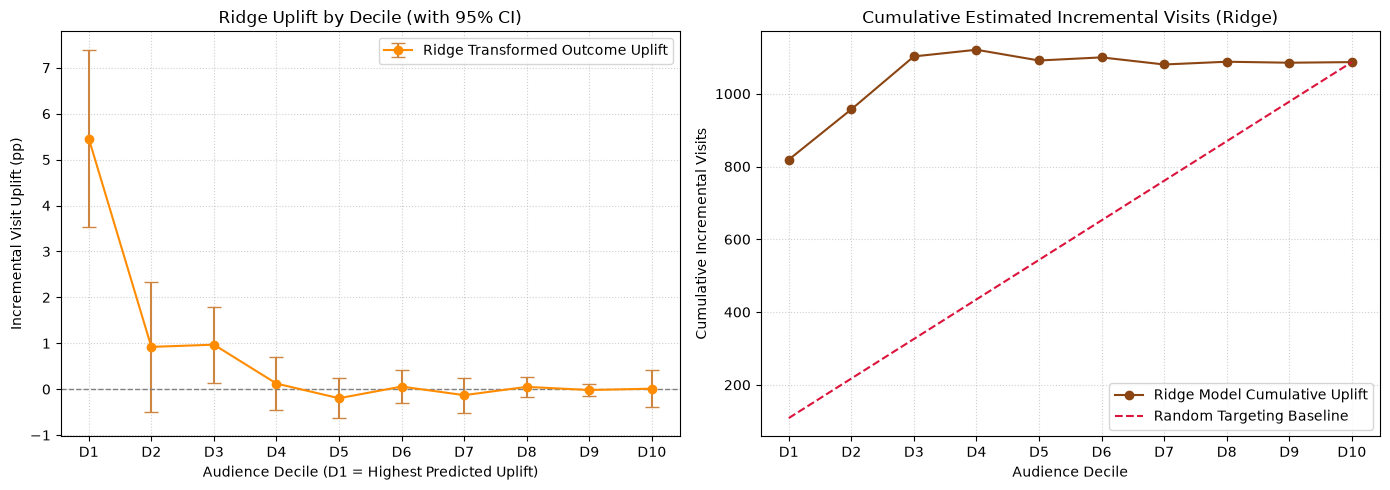

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Decile Uplift with 95% Confidence Intervals
x_indices = np.arange(len(val_ridge_eval))
axes[0].errorbar(
    x_indices,
    val_ridge_eval["uplift"] * 100,  # Convert to percentage points
    yerr=1.96 * val_ridge_eval["se"] * 100,
    fmt='o-',
    capsize=5,
    color="darkorange",
    ecolor="peru",
    label="Ridge Transformed Outcome Uplift"
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels(val_ridge_eval["decile"])
axes[0].set_title("Ridge Uplift by Decile (with 95% CI)")
axes[0].set_xlabel("Audience Decile (D1 = Highest Predicted Uplift)")
axes[0].set_ylabel("Incremental Visit Uplift (pp)")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend()

# Plot 2: Cumulative Incremental Visits vs Random Baseline
total_inc = val_ridge_eval["est_incremental_visits"].sum()
random_baseline = np.linspace(total_inc / 10, total_inc, 10)

axes[1].plot(
    val_ridge_eval["decile"],
    val_ridge_eval["cum_est_incremental_visits"],
    marker="o",
    color="saddlebrown",
    label="Ridge Model Cumulative Uplift"
)
axes[1].plot(
    val_ridge_eval["decile"],
    random_baseline,
    linestyle="--",
    color="crimson",
    label="Random Targeting Baseline"
)
axes[1].set_title("Cumulative Estimated Incremental Visits (Ridge)")
axes[1].set_xlabel("Audience Decile")
axes[1].set_ylabel("Cumulative Incremental Visits")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

### 6) Graph Interpretations Summary
If we are assuming there is an ad campaign for SolePeak Footwear, then this splits the potential audience into 10 equal groups (Deciles D1 through D10) based on the model's prediction of who is **most likely to visit because of an ad**, not just who visits anyway.

#### **Left Graph: "Ridge Uplift by Decile (with 95% CI)"**
- **What the bars and dots show:** The dots show the extra percentage of people who visited because they received an ad in each group. The vertical error bars represent our statistical uncertainty (a 95% confidence range).
- **The standout group (D1):** In D1 (the top 10% of users your model ranked highest), the ad produced a dramatic lift—around +5.5 percentage points extra visits. The bottom of its error bar stays comfortably above 3.5%, meaning this effect is real and not just random luck.
- **The rest of the audience (D2 to D10):** From D2 downward, the lift drops sharply to near zero. From D4 to D10, the dots hover directly on the dashed 0 line, and the error bars cross zero. This means showing ads to the bottom 60–70% of the audience produced virtually no measurable extra visits compared to not showing them ads at all. 

In a technical sense:
- Causal Incrementality & Decile Calibration is represented in the left graph. Decile 1 exhibits an empirical ITT uplift of $\approx 5.45$ percentage points ($95\%\text{ CI: } [3.53\%, 7.37\%]$). Deciles 2 and 3 retain small positive lifts ($\approx 0.9\%$ and $\approx 1.0\%$), but their confidence intervals border or overlap with 0 (D2 crosses 0, D3 barely sits above).
- The model achieves strong causal separation in the highest bin, but the ranking degrades into a flat tail from D4 through D10. Point estimates for D4–D10 oscillate tightly around $0.0\%$ (e.g., D5 is slightly negative at $\approx -0.19\%$, D8 is $\approx +0.05\%$), with confidence bands spanning across zero.
- Crucially, the tail shows no statistically significant negative uplift. In advertising uplift modeling, negative uplift corresponds to **"sleeping dogs"** (users who get annoyed by an ad and become less likely to visit/convert). Here, unreached segments are simply indifferent ("unresponsive" or "organic baseline visitors").

#### **Right Graph: "Cumulative Estimated Incremental Visits"**
- **The dashed red line (Random Targeting):** If you randomly picked people to advertise to, you would gain incremental visits at a steady, slow pace until reaching the total campaign effect (~1,100 incremental visits across the whole validation cohort).
- **The brown curve (Model Targeting):** By targeting the highest-ranked users first, the model captures over 800 incremental visits in just the first 10% (D1) and peaks at over 1,100 visits by D3–D4 (top 30–40%). 
- **The takeaway:** After the top 30–40%, the brown line completely flattens out. Spending money on the remaining 60–70% of the audience adds zero additional visits. 

In a technical sense:
- Uplift Curve Dynamics & Budget Optimization is represented in the right graph. The cumulative curve demonstrates exceptional initial concavity (high causal concentration). Target decile D1 captures $\approx 818$ of the cohort's $\approx 1,090$ total incremental visits—roughly 75% of the total available campaign incrementality from just 10% of audience delivery. 
- The cumulative curve crests at D3–D4 ($\approx 1,120$ incremental visits) and becomes completely horizontal through D10. Minor dips (e.g., at D5 and D7) represent slight empirical sampling noise around zero treatment effect.
- For maximizing ROAS (return on ad spend):
    - In a retail media partnership between SolePeak and MarketBridge, a conventional ad buy might purchase 100% of available impressions across the eligible user pool.
    - **These graphs prove that capping the campaign cut-off at D1 (or at most D3) captures essentially all incremental value while eliminating 70% to 90% of wasted ad spend and bid costs.**
- **Within Data Clean Room & Governance Context:** Because the individual features f0 through f11 are left hidden to what they actually represent, SolePeak and MarketBridge cannot attribute this lift to a named demographic trait. However, within the clean room protocol, MarketBridge can deploy this Ridge score upstream to construct an approved high-lift targeting cohort (D1–D3), delivering maximum incremental return without exporting identifiable customer-level records.